# 1. Open datasets

In [1]:
#%pip install "setuptools<82"
#%pip install PyTDC

%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys

# Works when running from the project root or notebooks/
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import canonicalize_smiles

In [3]:
from pathlib import Path

from tdc.single_pred import ADME, Tox
import pandas as pd

# Save datasets in the project-level data/raw directory
raw_dir = Path("../data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

# Load regression dataset
solubility = ADME(name="Solubility_AqSolDB")
df_reg = solubility.get_data()
df_reg.to_csv(raw_dir / "solubility_aqsoldb.tab", sep="\t", index=False)

# Load classification dataset
herg = Tox(name="hERG")
df_clf = herg.get_data()
df_clf.to_csv(raw_dir / "herg.tab", sep="\t", index=False)

# Preview datasets and report shapes
display(df_reg.head(10))
display(df_clf.head(10))
print("Regression:", df_reg.shape)
print("Classification:", df_clf.shape)

Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!


,Drug_ID,Drug,Y
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065
5,vinyltoluene,C=Cc1cccc(C)c1,-3.123150
6,3-(3-ethylcyclopentyl)propanoic acid,CCC1CCC(CCC(=O)O)C1,-3.286116
7,"11,16,17,21-tetrahydroxypregna-1,4-diene-3,20-...",CC12C=CC(=O)C=C1CCC1C2C(O)CC2(C)C1CC(O)C2(O)C(...,-2.664549
8,bis(4-fluorophenyl)methanone,O=C(c1ccc(F)cc1)c1ccc(F)cc1,-4.396652
9,1-[2-(benzoyloxy)propoxy]propan-2-yl benzoate ...,O=C(OCCCOCCCOC(=O)c1ccccc1)c1ccccc1,-4.595503


,Drug_ID,Drug,Y
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0
5,BENPERIDOL,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F)cc1,1.0
6,NaN,Fc1ccc(-n2cc(C3CCN(CCN4CCNC4=S)CC3)c3ccccc32)cc1,1.0
7,BMCL20031829_03,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccccc23)CC1,1.0
8,VANOXERINE HYDROCHLORIDE,Fc1ccc(C(OCCN2CCN(CCCc3ccccc3)CC2)c2ccc(F)cc2)cc1,1.0
9,L-691121,CS(=O)(=O)Nc1ccc2c(c1)C(=O)CC1(CCN(CCc3ccc4non...,1.0


Regression: (9982, 3)
Classification: (655, 3)


# 2. Check for missing or invalid values

In [4]:
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import MolFromSmiles

In [5]:
#Solubility dataset

df_reg = solubility.get_data()

df_reg = df_reg.rename(columns={
    "Drug": "SMILES",
    "Y": "Solubility"
})

print("Dataset: Solubility_AqSolDB")
print("Target: Aqueous solubility")
print("Original rows:", len(df_reg))


print("Missing SMILES:", df_reg["SMILES"].isna().sum())
print("Missing solubility:", df_reg["Solubility"].isna().sum())

print(df_reg.columns)





Dataset: Solubility_AqSolDB
Target: Aqueous solubility
Original rows: 9982
Missing SMILES: 0
Missing solubility: 0
Index(['Drug_ID', 'SMILES', 'Solubility'], dtype='object')


In [6]:
#hERG dataset

df_clf = herg.get_data()

df_clf = df_clf.rename(columns={
    "Drug": "SMILES",
    "Y": "Blocking_status"
})

print("Dataset: hERG")
print("Target: Blocking status") #if the molecule is either blocking or not
print("Original rows:", len(df_clf))


print("Missing SMILES:", df_clf["SMILES"].isna().sum())
print("Missing hERG:", df_clf["Blocking_status"].isna().sum())

Dataset: hERG
Target: Blocking status
Original rows: 655
Missing SMILES: 0
Missing hERG: 0


# 3. Solubility dataset analysis

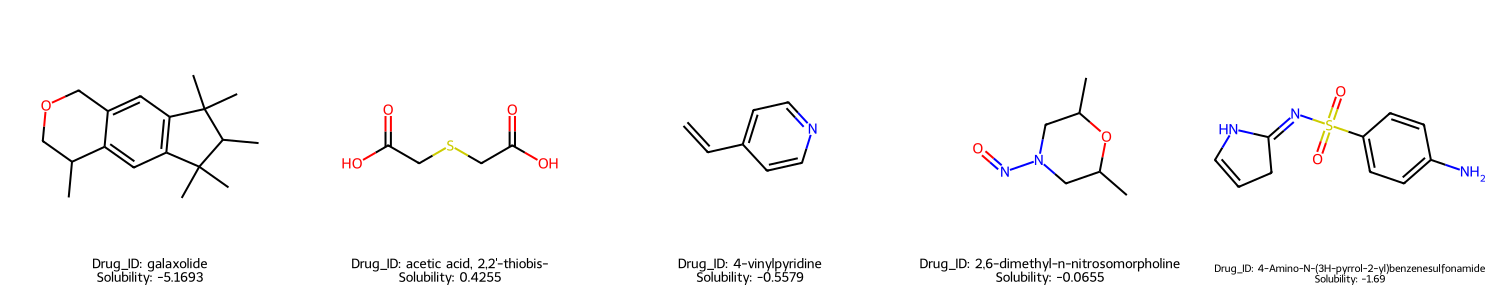

In [7]:
# Visualization of some molecules from the dataset
n = 5
df_sample = df_reg.sample(n)

smiles = df_sample["SMILES"].values
legends = [
    f"Drug_ID: {drug_id}\nSolubility: {solubility_value}"
    for drug_id, solubility_value in zip(
        df_sample["Drug_ID"], df_sample["Solubility"]
    )
]
molecs = [Chem.MolFromSmiles(smile) for smile in smiles]

display(Draw.MolsToGridImage(
    molecs,
    molsPerRow=5,
    subImgSize=(300, 300),
    legends=legends
))

In [8]:
# Convert solubility values to numbers
numeric_target = pd.to_numeric(df_reg["Solubility"], errors="coerce")

# Identify NaN, infinite values and failed conversions
invalid_target = ~np.isfinite(numeric_target)

print("Invalid solubility values:", invalid_target.sum())

if invalid_target.any():
    display(df_reg.loc[invalid_target])
    raise ValueError("Invalid solubility values to inspect.")

# Keep the numeric values if all checks pass
df_reg["Solubility"] = numeric_target

print("All solubility targets are valid.")

Invalid solubility values: 0
All solubility targets are valid.


In [9]:
#canonicalization
df_reg["Canonical_smiles"] = df_reg["SMILES"].apply(canonicalize_smiles)

# Count invalid structures before removing them
print("Invalid SMILES — solubility:",
      df_reg["Canonical_smiles"].isna().sum())

# Keep only valid structures
df_reg = df_reg.dropna(subset=["Canonical_smiles"]).copy()
print("Remaining rows — solubility:", len(df_reg))


[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not removing hydrogen atom without neighbors
[18:36:44] WARNING: not r

Invalid SMILES — solubility: 0
Remaining rows — solubility: 9982


In [ ]:
# Identify SMILES containing multiple disconnected fragments.
# These fragments are separated by a literal "." in the SMILES
# and may represent salts or mixtures.
# regex=False ensures that "." is treated as a literal character.
n_multifragment = df_reg["Canonical_smiles"].str.contains(
    ".", regex=False, na=False
).sum()

print("Rows with multiple fragments:", n_multifragment)

Rows with multiple fragments: 1098


In [11]:
# Identify all rows sharing the same canonical SMILES.

dup = df_reg.duplicated(subset="Canonical_smiles", keep=False)
print("Rows involved in duplicates:", dup.sum())
print(
    "Distinct duplicated structures:",
    df_reg.loc[dup, "Canonical_smiles"].nunique()
)

Rows involved in duplicates: 0
Distinct duplicated structures: 0


count    9982.000000
mean       -2.889909
std         2.368154
min       -13.171900
25%        -4.326325
50%        -2.618173
75%        -1.209735
max         2.137682
Name: Solubility, dtype: float64


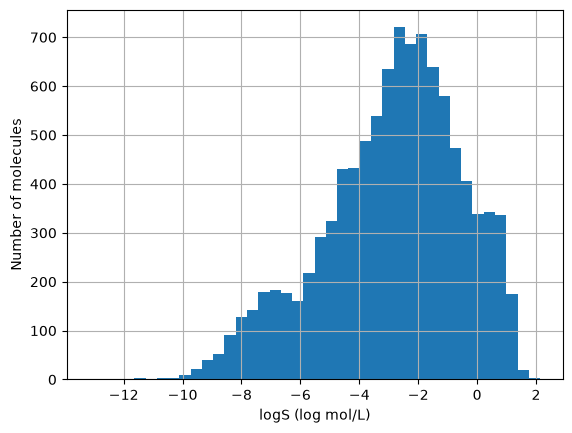

In [12]:
# Summarize solubility values and visualize how frequently they occur.

import matplotlib.pyplot as plt

print(df_reg["Solubility"].describe())
df_reg["Solubility"].hist(bins=40)
plt.xlabel("logS (log mol/L)")
plt.ylabel("Number of molecules")
plt.show()

The histogram shows the distribution of aqueous solubility, expressed as logS in mol/L. Most compounds have negative logS values; the median is about -2.62, corresponding to roughly 2.4 mmol/L. The long tail toward very low values indicates that some compounds are much less soluble than the majority.

# Remove missing values

In [13]:
initial_rows = len(df_reg)

df_reg = df_reg.dropna(subset=["SMILES", "Solubility"]).copy()

print("Rows removed:", initial_rows - len(df_reg))
print("Rows remaining:", len(df_reg))
display (df_reg.head())

initial_rows = len(df_clf)

df_clf = df_clf.dropna(subset=["SMILES", "Blocking_status"]).copy()

print("Rows removed:", initial_rows - len(df_clf))
print("Rows remaining:", len(df_clf))
display (df_clf.head())

Rows removed: 0
Rows remaining: 9982


,Drug_ID,SMILES,Solubility,Canonical_smiles
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127,CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-]
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767,O=C1Nc2cccc3cccc1c23
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078,O=Cc1ccc(Cl)cc1
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409,CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...


Rows removed: 0
Rows remaining: 655


,Drug_ID,SMILES,Blocking_status
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0
